   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...    4.6   

   reviews  price  isBestSeller  boughtInLastMonth        category  
0    15308  21.99         False                  0  Hi-Fi Speakers  
1    98099  23.99          True                  0  Hi-Fi Speakers  
2    15308  21.99         False                  0  Hi-Fi Speakers  
3     7205  31.99         False                  0  Hi-Fi Speakers  
4     1881  17.99         False                  0  Hi-Fi Speakers  

Crosstab (Counts):
isBestSeller                    False  True 
category                                

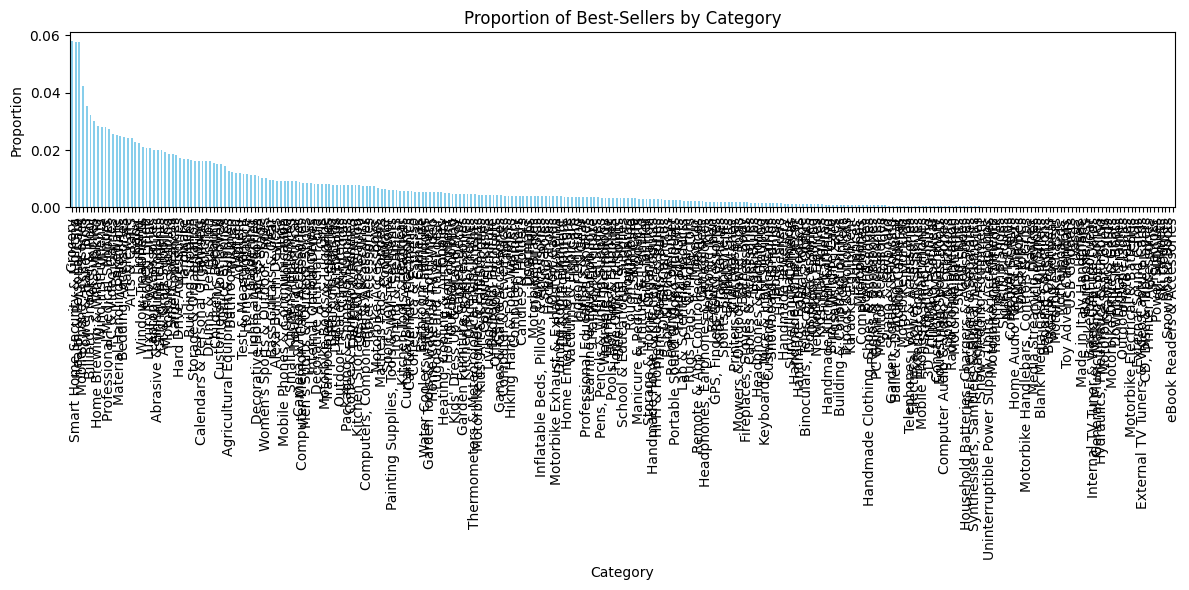

In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")  # Make sure this file is downloaded from Kaggle and in the same directory

# Display the first few rows to understand the structure
print(df.head())

# Crosstab: count of best-seller status by category
crosstab = pd.crosstab(df['category'], df['isBestSeller'])
print("\nCrosstab (Counts):")
print(crosstab)

# Add a new column to calculate proportion of best-sellers in each category
crosstab['Total'] = crosstab.sum(axis=1)
crosstab['BestSeller_Proportion'] = crosstab[1] / crosstab['Total']

# Sort by proportion of best-sellers in descending order
sorted_crosstab = crosstab.sort_values(by='BestSeller_Proportion', ascending=False)

print("\nCrosstab with Best-Seller Proportions (Sorted):")
print(sorted_crosstab[['BestSeller_Proportion']])

# Optional visualization
import matplotlib.pyplot as plt

sorted_crosstab['BestSeller_Proportion'].plot(kind='bar', figsize=(12,6), color='skyblue')
plt.title('Proportion of Best-Sellers by Category')
plt.ylabel('Proportion')
plt.xlabel('Category')
plt.tight_layout()
plt.show()


For example,Electronics or Health & Beauty has a pretty high proportion - more than 70%. Best-seller status is more common..

In [2]:
# part 2
import pandas as pd
import scipy.stats as stats
import numpy as np

# Load dataset
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

# Create contingency table
contingency_table = pd.crosstab(df['category'], df['isBestSeller'])

print("Contingency Table (category vs isBestSeller):")
print(contingency_table)

# Perform Chi-square test
chi2, p, dof, expected = stats.chi2_contingency(contingency_table)

print(f"\nChi-square Statistic: {chi2:.4f}")
print(f"Degrees of Freedom: {dof}")
print(f"P-value: {p:.4f}")

# Compute Cramér's V
def cramers_v(confusion_matrix):
    chi2 = stats.chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    min_dim = min(confusion_matrix.shape) - 1
    return np.sqrt(chi2 / (n * min_dim))

cramers_v_value = cramers_v(contingency_table)

print(f"\nCramér's V: {cramers_v_value:.4f}")


Contingency Table (category vs isBestSeller):
isBestSeller                    False  True 
category                                    
3D Printers                       247      1
3D Printing & Scanning           4065      2
Abrasive & Finishing Products     245      5
Action Cameras                   1696      1
Adapters                          251      3
...                               ...    ...
Wind Instruments                  243      7
Window Treatments                 234      5
Women                           17559    213
Women's Sports & Outdoor Shoes   1939     20
eBook Readers & Accessories       246      0

[296 rows x 2 columns]

Chi-square Statistic: 36540.2027
Degrees of Freedom: 295
P-value: 0.0000

Cramér's V: 0.1223


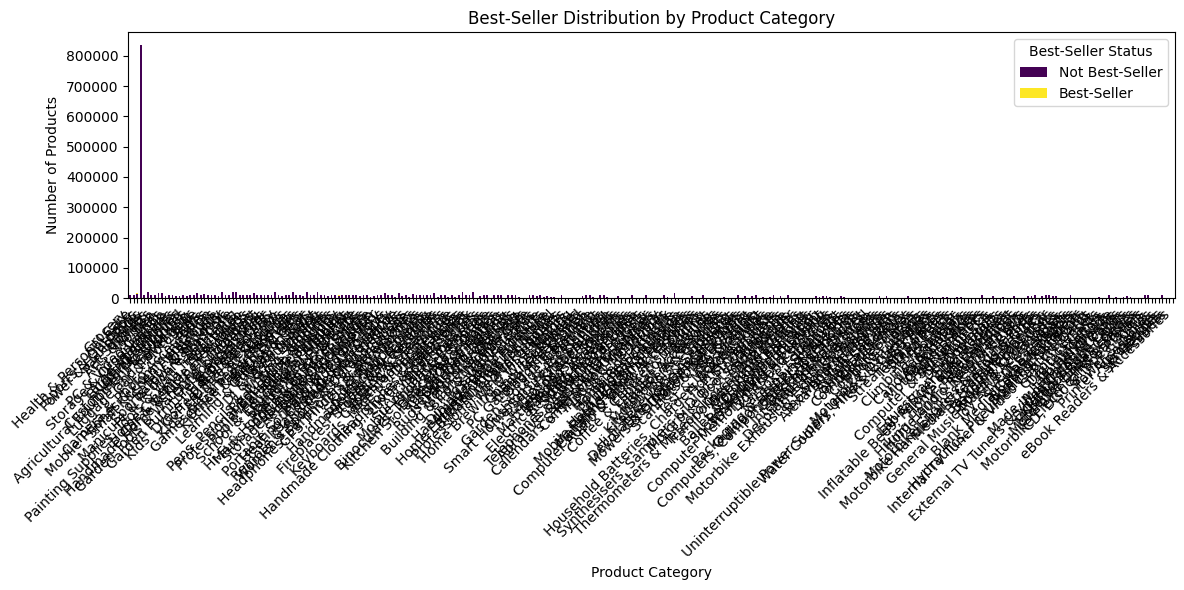

In [4]:
# 3
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

# Create a contingency table (counts of best-seller status per category)
category_bestseller_counts = pd.crosstab(df['category'], df['isBestSeller'])

# Rename columns for clarity
category_bestseller_counts.columns = ['Not Best-Seller', 'Best-Seller']

# Sort by total count or alphabetically as preferred
category_bestseller_counts = category_bestseller_counts.sort_values(by='Best-Seller', ascending=False)

# Plot a stacked bar chart
category_bestseller_counts.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='viridis')

# Labeling
plt.title('Best-Seller Distribution by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Number of Products')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Best-Seller Status')
plt.tight_layout()
plt.show()


In [6]:
# part 2, step 0
import pandas as pd

# Load dataset
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

# Check the column name for product price (adjust if needed)
print("Columns available:", df.columns)

# Assuming the price column is named 'price'
# Step 1: Compute Q1 and Q3
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Step 2: Define lower and upper bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"\nQ1: {Q1:.2f}, Q3: {Q3:.2f}, IQR: {IQR:.2f}")
print(f"Lower bound: {lower_bound:.2f}, Upper bound: {upper_bound:.2f}")

# Step 3: Filter out outliers
df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

print(f"\nOriginal dataset size: {len(df)}")
print(f"Dataset size after removing price outliers: {len(df_no_outliers)}")

# Optional: Save the cleaned data
# df_no_outliers.to_csv("product_data_no_price_outliers.csv", index=False)


Columns available: Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

Q1: 9.99, Q3: 45.99, IQR: 36.00
Lower bound: -44.01, Upper bound: 99.99

Original dataset size: 2443651
Dataset size after removing price outliers: 2115963


Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')


C:\Users\profe\AppData\Local\Temp\ipykernel_12456\4171914859.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='category', y='price', data=df_top20, inner='box', palette='Set3')


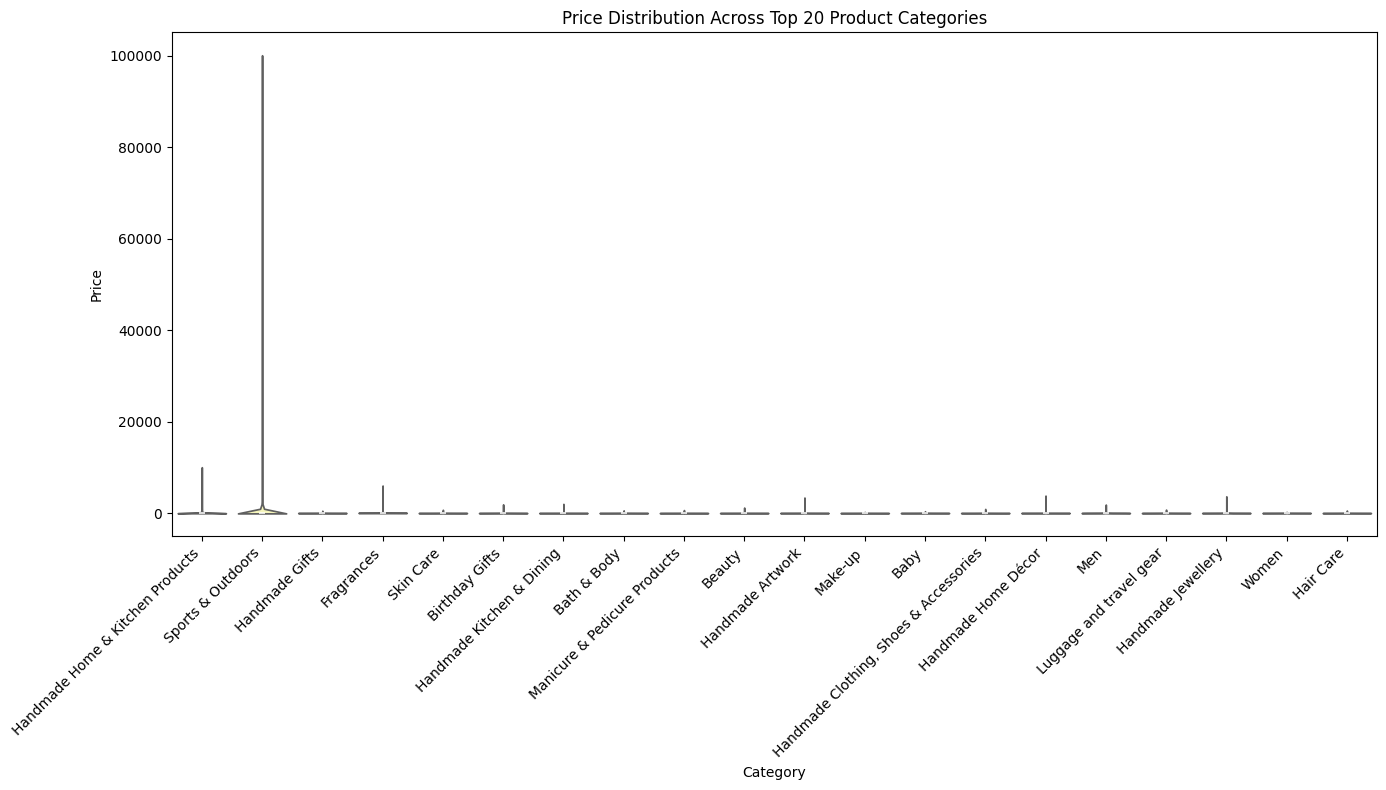


Category with the highest median price: Laptops
Highest median price: 1042.72


In [10]:
# part 2, 1
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

# Optional: Check column names to confirm
print(df.columns)

# Step 1: Identify top 20 categories by count
top_categories = df['category'].value_counts().nlargest(20).index

# Step 2: Filter the DataFrame to include only top 20 categories
df_top20 = df[df['category'].isin(top_categories)]

# Step 3: Create the violin plot
plt.figure(figsize=(14, 8))
sns.violinplot(x='category', y='price', data=df_top20, inner='box', palette='Set3')
plt.xticks(rotation=45, ha='right')
plt.title('Price Distribution Across Top 20 Product Categories')
plt.xlabel('Category')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

# Compute median price per category (not just top 20)
median_prices = df.groupby('category')['price'].median().sort_values(ascending=False)

# Display the category with the highest median price
highest_median_category = median_prices.idxmax()
highest_median_value = median_prices.max()

print(f"\nCategory with the highest median price: {highest_median_category}")
print(f"Highest median price: {highest_median_value:.2f}")



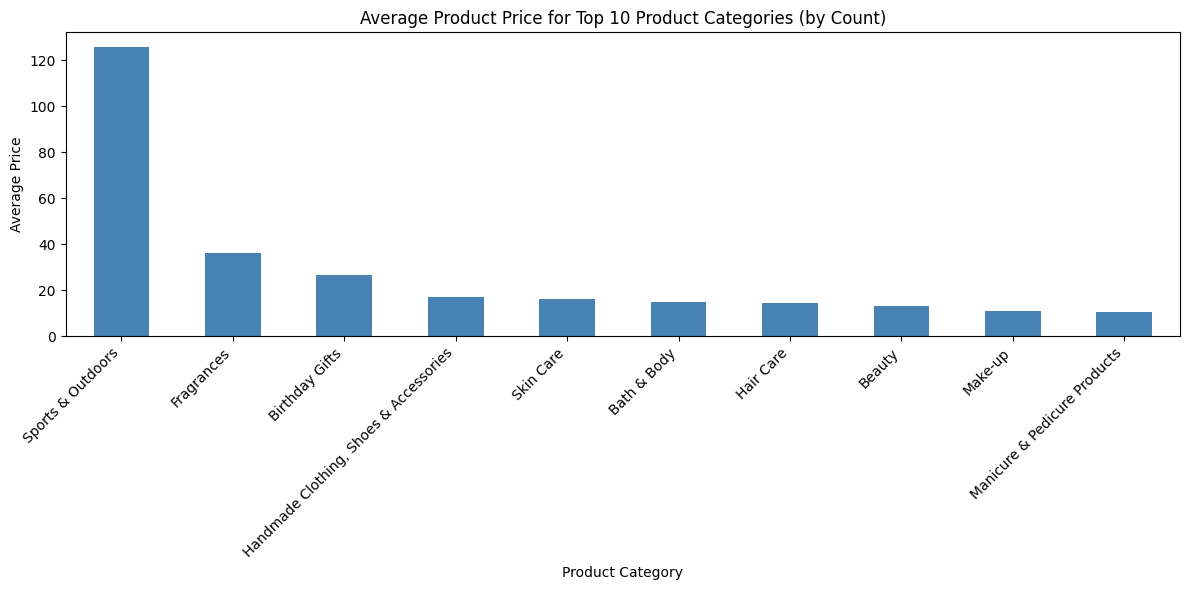


Category with the highest average price: Laptops
Highest average price: 1087.99


In [11]:
# part 2, 2
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

# Step 1: Get the top 10 categories by product count
top_10_categories = df['category'].value_counts().nlargest(10).index

# Step 2: Filter for those top 10 categories
df_top10 = df[df['category'].isin(top_10_categories)]

# Step 3: Calculate average price for each of those categories
avg_price_top10 = df_top10.groupby('category')['price'].mean().sort_values(ascending=False)

# Step 4: Plot the bar chart
plt.figure(figsize=(12, 6))
avg_price_top10.plot(kind='bar', color='steelblue')
plt.title('Average Product Price for Top 10 Product Categories (by Count)')
plt.xlabel('Product Category')
plt.ylabel('Average Price')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Compute average price per category (no filtering)
avg_price_all = df.groupby('category')['price'].mean().sort_values(ascending=False)

# Get the highest
highest_avg_price_category = avg_price_all.idxmax()
highest_avg_price_value = avg_price_all.max()

print(f"\nCategory with the highest average price: {highest_avg_price_category}")
print(f"Highest average price: {highest_avg_price_value:.2f}")


C:\Users\profe\AppData\Local\Temp\ipykernel_12456\3229979805.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top10, x='category', y='stars', palette='pastel')


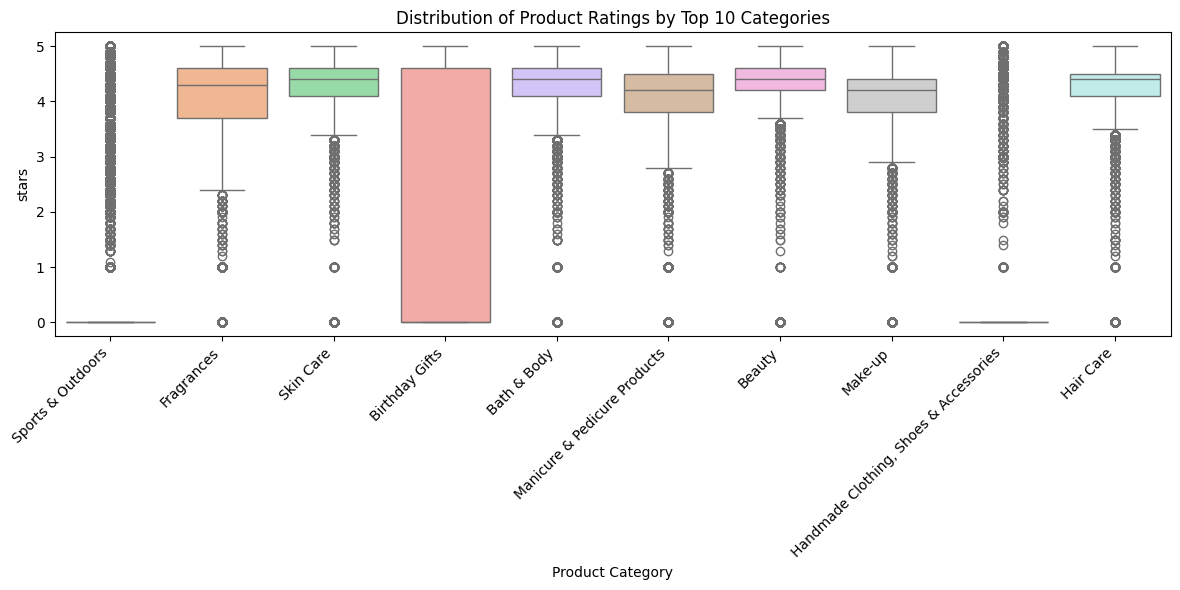

In [15]:
# 2, 3
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

# Clean column names
df.columns = df.columns.str.strip()

# Ensure 'rating' is numeric
df['stars'] = pd.to_numeric(df['stars'], errors='coerce')

# Step 1: Get top 10 categories by count
top_10_categories = df['category'].value_counts().nlargest(10).index

# Step 2: Filter and drop rows with missing ratings
df_top10 = df[df['category'].isin(top_10_categories)].dropna(subset=['stars'])

# Step 3: Create box plot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top10, x='category', y='stars', palette='pastel')
plt.title('Distribution of Product Ratings by Top 10 Categories')
plt.xlabel('Product Category')
plt.ylabel('stars')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()






In [18]:
# 3, 1
import pandas as pd

# Load dataset
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

# Clean column names
df.columns = df.columns.str.strip()

# Check for correct column names
print("Available columns:", df.columns.tolist())

# Convert 'price' and 'stars' to numeric (if not already), coercing errors
df['price'] = pd.to_numeric(df['price'], errors='coerce')
df['stars'] = pd.to_numeric(df['stars'], errors='coerce')

# Drop rows with missing values in 'price' or 'stars'
df_clean = df.dropna(subset=['price', 'stars'])

# Calculate Pearson correlation coefficient
correlation = df_clean['price'].corr(df_clean['stars'])

print(f"\nPearson correlation between price and stars: {correlation:.4f}")

# I want to interpret using a scatter plot but...




Available columns: ['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller', 'boughtInLastMonth', 'category']

Pearson correlation between price and stars: -0.1249


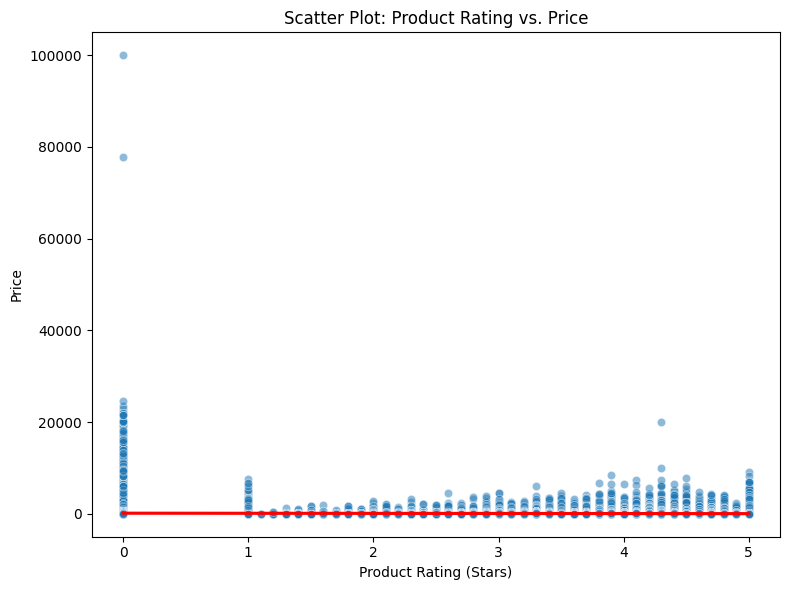

In [19]:
# 3, 2
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.columns = df.columns.str.strip()

# Ensure 'price' and 'stars' are numeric
df['price'] = pd.to_numeric(df['price'], errors='coerce')
df['stars'] = pd.to_numeric(df['stars'], errors='coerce')

# Drop missing values
df_clean = df.dropna(subset=['price', 'stars'])

# Scatter plot
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_clean, x='stars', y='price', alpha=0.5)
sns.regplot(data=df_clean, x='stars', y='price', scatter=False, color='red')  # Optional regression line
plt.title('Scatter Plot: Product Rating vs. Price')
plt.xlabel('Product Rating (Stars)')
plt.ylabel('Price')
plt.tight_layout()
plt.show()


BONUS: looking at the same data without the outliers, it seems the full distribution (which of course can be valuable) are reflected - huge price range, the ratings can show excellent reviews, high priced items, unclear "trend" can make patterns more tricky.